# 00 — Comprensión de los datos

## Objetivo

Conocer el dataset antes de tocarlo: qué tablas trae, cuánto pesa cada una, qué información
contiene y **cuáles sirven para predecir el ganador de un mapa**. Al final de este cuadernillo
debe quedar claro cuál es la unidad de análisis, qué tablas se van a usar y qué problemas
habrá que resolver en los siguientes pasos.

**Objetivo del proyecto:** predecir qué equipo gana un mapa de Valorant Champions Tour (VCT)
*antes de que se juegue*.

**Origen de los datos:** dataset público de Kaggle
([Valorant Champion Tour data](https://www.kaggle.com/datasets/ryanluong1/valorant-champion-tour-2021-2023-data)),
extraído del sitio de estadísticas vlr.gg. Cubre los años 2021 a 2026.

## 1. Preparación

Las funciones que se usan en varios cuadernillos viven en la carpeta `src/`. Aquí se importan
las rutas del proyecto, la función que lee una tabla de todos los años y las utilidades de gráficos.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt

from src.config import RAW_DIR, TABLES_DIR, load_config
from src.data_loading import load_table, load_ids
from src.plotting import set_style, save_fig

set_style()
pd.set_option("display.max_columns", 50)
config = load_config()
config["years"]

[2021, 2022, 2023, 2024, 2025, 2026]

## 2. Inventario de tablas

El dataset viene organizado en una carpeta por año (`vct_2021` … `vct_2026`) y, dentro de cada
una, cuatro subcarpetas: `agents`, `ids`, `matches` y `players_stats`. Antes de abrir nada,
se cuenta cuántas filas y cuánto pesa cada archivo. Las filas se cuentan leyendo saltos de
línea, sin cargar los archivos en memoria, porque el conjunto completo pesa más de 1 GB.

In [2]:
def count_rows(path):
    with open(path, "rb") as f:
        return sum(chunk.count(b"\n") for chunk in iter(lambda: f.read(1 << 20), b"")) - 1

inventory = pd.DataFrame([
    {
        "year": int(path.parts[-3][-4:]),
        "table": f"{path.parts[-2]}/{path.name}",
        "rows": count_rows(path),
        "columns": len(pd.read_csv(path, nrows=0).columns),
        "size_mb": round(path.stat().st_size / 1e6, 1),
    }
    for path in sorted(RAW_DIR.glob("vct_*/*/*.csv"))
])
inventory.to_csv(TABLES_DIR / "00_inventario_tablas.csv", index=False)

print(f"Archivos: {len(inventory)}  |  Tablas distintas: {inventory['table'].nunique()}  |  "
      f"Tamaño total: {inventory['size_mb'].sum() / 1000:.2f} GB")
inventory.pivot(index="table", columns="year", values="rows")

Archivos: 126  |  Tablas distintas: 21  |  Tamaño total: 1.36 GB


year,2021,2022,2023,2024,2025,2026
table,,,,,,
agents/agents_pick_rates.csv,192120,132336,17712,24840,30294,21547
agents/maps_stats.csv,8005,5514,738,1035,1122,743
agents/teams_picked_agents.csv,224050,131546,11751,15647,18396,11848
ids/players_ids.csv,11190,7568,284,260,349,284
ids/teams_ids.csv,2741,1572,51,44,58,49
ids/tournaments_stages_match_types_ids.csv,1777,1076,137,197,202,132
ids/tournaments_stages_matches_games_ids.csv,14489,8864,830,1104,1277,886
matches/draft_phase.csv,3378,7432,1898,2604,2988,2052
matches/eco_rounds.csv,363518,358798,33032,34514,25182,28944


Todas las tablas existen en los seis años, con la misma estructura. Lo que cambia mucho es el
volumen: se revisa el peso por año.

In [3]:
inventory.groupby("year")["size_mb"].sum().round(0).to_frame("size_mb").T

year,2021,2022,2023,2024,2025,2026
size_mb,634.0,542.0,44.0,49.0,52.0,38.0


## 3. La tabla central: `matches/maps_scores.csv`

Esta tabla tiene **una fila por mapa jugado**, con los dos equipos y el marcador final. Es la
que define la unidad de análisis y de donde sale la variable objetivo.

In [4]:
maps_scores = load_table("matches/maps_scores.csv")
print(maps_scores.shape)
maps_scores.head()

(27484, 17)


,Tournament,Stage,Match Type,Match Name,Map,Team A,Team A Score,Team A Attacker Score,Team A Defender Score,Team A Overtime Score,Team B,Team B Score,Team B Attacker Score,Team B Defender Score,Team B Overtime Score,Duration,Year
0,Valorant Champions 2021,Group Stage,Opening (D),Vision Strikers vs FULL SENSE,Haven,Vision Strikers,13,9,4,NaN,FULL SENSE,5,2,3.0,NaN,59:11,2021
1,Valorant Champions 2021,Group Stage,Opening (D),Vision Strikers vs FULL SENSE,Breeze,Vision Strikers,13,9,4,NaN,FULL SENSE,5,2,3.0,NaN,44:30,2021
2,Valorant Champions 2021,Group Stage,Opening (C),Team Vikings vs Crazy Raccoon,Icebox,Team Vikings,13,6,7,NaN,Crazy Raccoon,9,3,6.0,NaN,59:48,2021
3,Valorant Champions 2021,Group Stage,Opening (C),Team Vikings vs Crazy Raccoon,Haven,Team Vikings,13,6,7,NaN,Crazy Raccoon,8,2,6.0,NaN,52:48,2021
4,Valorant Champions 2021,Group Stage,Opening (D),FNATIC vs Cloud9,Icebox,FNATIC,13,7,6,NaN,Cloud9,11,6,5.0,NaN,59:50,2021


Mapas y torneos por año. El número de torneos ayuda a entender por qué el volumen es tan desigual.

In [5]:
per_year = maps_scores.groupby("Year").agg(maps=("Map", "size"), tournaments=("Tournament", "nunique"))
per_year

,maps,tournaments
Year,,
2021,14503,142
2022,8884,58
2023,830,10
2024,1104,15
2025,1277,15
2026,886,10


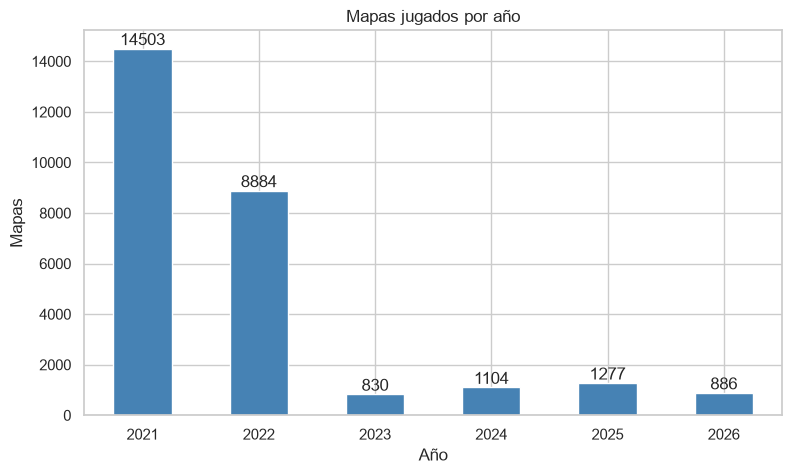

In [6]:
ax = per_year["maps"].plot.bar(color="steelblue")
ax.set(title="Mapas jugados por año", xlabel="Año", ylabel="Mapas")
ax.bar_label(ax.containers[0])
plt.xticks(rotation=0)
save_fig("00_mapas_por_anio")
plt.show()

En 2021 y 2022 el circuito incluía decenas de clasificatorios regionales abiertos; desde 2023
VCT pasó a un formato de ligas con equipos fijos, con muchos menos torneos. Por eso los dos
primeros años concentran la gran mayoría de los mapas.

## 4. Tablas con información de lo que pasó *dentro* de cada mapa

Estas tablas describen el rendimiento de jugadores y equipos en cada mapa. Se revisan las
tres que más interesan.

### `matches/overview.csv` — estadísticas por jugador y mapa

In [7]:
overview_2024 = load_table("matches/overview.csv", years=[2024])
print(overview_2024.shape)
overview_2024.head(4)

(46152, 22)


,Tournament,Stage,Match Type,Match Name,Map,Player,Team,Agents,Rating,Average Combat Score,Kills,Deaths,Assists,Kills - Deaths (KD),"Kill, Assist, Trade, Survive %",Average Damage Per Round,Headshot %,First Kills,First Deaths,Kills - Deaths (FKD),Side,Year
0,Valorant Champions 2024,Group Stage,Opening (B),Gen.G vs Sentinels,Haven,t3xture,Gen.G,jett,1.60,305.0,24.0,12.0,4.0,12.0,81%,188.0,31%,3.0,4.0,-1.0,both,2024
1,Valorant Champions 2024,Group Stage,Opening (B),Gen.G vs Sentinels,Haven,t3xture,Gen.G,jett,1.71,364.0,12.0,5.0,2.0,7.0,89%,216.0,37%,2.0,2.0,0.0,attack,2024
2,Valorant Champions 2024,Group Stage,Opening (B),Gen.G vs Sentinels,Haven,t3xture,Gen.G,jett,1.52,261.0,12.0,7.0,2.0,5.0,75%,168.0,24%,1.0,2.0,-1.0,defend,2024
3,Valorant Champions 2024,Group Stage,Opening (B),Gen.G vs Sentinels,Haven,Meteor,Gen.G,killjoy,1.23,221.0,17.0,10.0,4.0,7.0,76%,140.0,26%,1.0,4.0,-3.0,both,2024


Dos detalles importantes de esta tabla: cada jugador aparece tres veces por mapa (columna
`Side`: ambos lados, ataque y defensa) y hay una fila agregada `All Maps` por partido. Si no
se filtran, las estadísticas se contarían varias veces.

In [8]:
print(overview_2024["Side"].value_counts().to_dict())
print(sorted(overview_2024["Map"].unique()))

{'both': 15384, 'attack': 15384, 'defend': 15384}
['Abyss', 'All Maps', 'Ascent', 'Bind', 'Breeze', 'Haven', 'Icebox', 'Lotus', 'Split', 'Sunset']


### `matches/eco_stats.csv` — economía por equipo y mapa

Incluye cuántas rondas de pistola ganó cada equipo y cómo le fue según el tipo de compra.

In [9]:
eco_2024 = load_table("matches/eco_stats.csv", years=[2024])
print(eco_2024["Type"].unique())
eco_2024.head(5)

<StringArray>
['Pistol Won', 'Eco (won)', '$ (won)', '$$ (won)', '$$$ (won)']
Length: 5, dtype: str


,Tournament,Stage,Match Type,Match Name,Map,Team,Type,Initiated,Won,Year
0,Valorant Champions 2024,Group Stage,Opening (B),Gen.G vs Sentinels,Haven,Gen.G,Pistol Won,NaN,2,2024
1,Valorant Champions 2024,Group Stage,Opening (B),Gen.G vs Sentinels,Haven,Gen.G,Eco (won),2.0,2,2024
2,Valorant Champions 2024,Group Stage,Opening (B),Gen.G vs Sentinels,Haven,Gen.G,$ (won),1.0,0,2024
3,Valorant Champions 2024,Group Stage,Opening (B),Gen.G vs Sentinels,Haven,Gen.G,$$ (won),6.0,4,2024
4,Valorant Champions 2024,Group Stage,Opening (B),Gen.G vs Sentinels,Haven,Gen.G,$$$ (won),12.0,7,2024


### `matches/draft_phase.csv` — vetos y elección de mapas

Registra qué equipo vetó (`ban`) o eligió (`pick`) cada mapa. Es información que **se conoce
antes de jugar**.

In [10]:
draft_2024 = load_table("matches/draft_phase.csv", years=[2024])
draft_2024.head(7)

,Tournament,Stage,Match Type,Match Name,Team,Action,Map,Year
0,Valorant Champions 2024,Group Stage,Opening (B),Gen.G vs Sentinels,Sentinels,ban,Icebox,2024
1,Valorant Champions 2024,Group Stage,Opening (B),Gen.G vs Sentinels,Gen.G,ban,Sunset,2024
2,Valorant Champions 2024,Group Stage,Opening (B),Gen.G vs Sentinels,Sentinels,pick,Haven,2024
3,Valorant Champions 2024,Group Stage,Opening (B),Gen.G vs Sentinels,Gen.G,pick,Ascent,2024
4,Valorant Champions 2024,Group Stage,Opening (B),Gen.G vs Sentinels,Sentinels,ban,Bind,2024
5,Valorant Champions 2024,Group Stage,Opening (B),Gen.G vs Sentinels,Gen.G,ban,Lotus,2024
6,Valorant Champions 2024,Group Stage,Opening (B),FunPlus Phoenix vs Team Heretics,FunPlus Phoenix,ban,Sunset,2024


## 5. Identificadores: `all_ids/all_matches_games_ids.csv`

Ninguna tabla trae la **fecha** del partido. Para un problema de predicción eso es crítico:
hay que saber qué partidos ocurrieron antes que otros. Lo que sí hay son los identificadores
que vlr.gg asigna a cada partido (`Match ID`) y a cada mapa (`Game ID`).

In [11]:
ids = load_ids()
ids.head(3)

,Tournament,Tournament ID,Stage,Stage ID,Match Type,Match Type ID,Match Name,Match ID,Map,Game ID,Year
0,Valorant Champions 2021,449,Group Stage,945,Opening (D),8272.0,Vision Strikers vs FULL SENSE,51282,Haven,57948.0,2021
1,Valorant Champions 2021,449,Group Stage,945,Opening (D),8272.0,Vision Strikers vs FULL SENSE,51282,Breeze,57949.0,2021
2,Valorant Champions 2021,449,Group Stage,945,Opening (C),8268.0,Team Vikings vs Crazy Raccoon,51278,Icebox,57936.0,2021


In [12]:
ids.groupby("Year")["Match ID"].agg(["min", "max", "count"])

,min,max,count
Year,,,
2021,8756,51296,14489
2022,60938,130691,8864
2023,167348,248283,830
2024,295605,378836,1104
2025,427991,542279,1277
2026,594740,684619,886


Los rangos de `Match ID` de cada año no se solapan y crecen con el tiempo: los IDs se asignan
en orden de creación. Se usarán como aproximación del orden cronológico (se valida con más
detalle en el cuadernillo 01).

## 6. ¿Qué tablas sirven para predecir?

La pregunta clave para cada tabla es: **¿esta información existe antes de que empiece el mapa?**

| Tabla | Qué contiene | ¿Se conoce antes del mapa? | Uso |
|---|---|---|---|
| `matches/maps_scores` | Marcador de cada mapa | No (es el resultado) | Variable objetivo e historial |
| `matches/overview` | Rating, ACS, kills… por jugador | No | Solo como historial de mapas **anteriores** |
| `matches/eco_stats` | Rondas de pistola y economía | No | Solo como historial de mapas **anteriores** |
| `matches/draft_phase` | Vetos y elecciones de mapa | Sí | Contexto previo |
| `all_ids/all_matches_games_ids` | IDs de partido y mapa | Sí | Orden cronológico |
| `matches/kills`, `rounds_kills`, `eco_rounds`, `win_loss_methods_*` | Detalle ronda a ronda | No | No se usan: mismo contenido que `overview`/`eco_stats` con más detalle del necesario |
| `agents/*`, `players_stats/*` | Agregados por torneo y etapa | No (resumen de todo el torneo) | No se usan como variables: mezclan partidos pasados y futuros |

Usar directamente las estadísticas del mismo mapa que se quiere predecir sería **fuga de
datos**: el modelo "adivinaría" que gana quien hizo más kills, algo que solo se sabe cuando el
mapa ya terminó.

## Conclusiones

1. **Unidad de análisis:** un mapa jugado. Hay 27 484 mapas en `maps_scores` entre 2021 y 2026.
2. **Variable objetivo:** se derivará del marcador (`Team A Score` vs `Team B Score`).
3. **Volumen muy desigual:** 2021 y 2022 suman 23 387 mapas (85 % del total) y 200 torneos;
   de 2023 en adelante hay entre 830 y 1 277 mapas por año. Esto condiciona la partición
   entrenamiento/prueba: los años recientes son pocos pero son los que mejor representan el VCT actual.
4. **Tablas elegidas:** `maps_scores` (objetivo e historial), `overview` y `eco_stats`
   (rendimiento en mapas anteriores), `draft_phase` (contexto previo) y `all_ids` (orden).
5. **Riesgo principal — fuga de datos:** casi todas las tablas describen lo que pasó durante
   el mapa. Solo pueden usarse como historial de mapas previos.
6. **No hay fechas:** el orden cronológico se aproximará con los IDs de vlr.gg.
7. **Detalles a limpiar:** `overview` repite cada jugador por lado (`Side`) y trae filas
   `All Maps`; los porcentajes vienen como texto (`"81%"`).

**Siguiente paso (cuadernillo 01):** unir todos los años, validar el orden cronológico,
limpiar los datos y construir la tabla base de mapas con la variable objetivo.